In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sbs

### Data Cleaning

In [19]:
df = pd.read_excel('data\\bakery_synthetic_dataset.csv.xlsx')
pd.set_option('display.max_columns', None)

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16569 entries, 0 to 16568
Data columns (total 41 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Transaction_ID        16569 non-null  object        
 1   Date                  16569 non-null  datetime64[ns]
 2   Time                  16569 non-null  object        
 3   Customer_ID           16569 non-null  object        
 4   Customer_Age          16569 non-null  int64         
 5   Customer_Gender       16569 non-null  object        
 6   Product               16569 non-null  object        
 7   Category              16569 non-null  object        
 8   Quantity              16569 non-null  int64         
 9   Unit_Price            16569 non-null  float64       
 10  Discount_Percentage   16569 non-null  float64       
 11  Discount_Amount       16569 non-null  float64       
 12  Selling_Price         16569 non-null  float64       
 13  Total_Bill      

In [21]:
df.describe()

,Date,Customer_Age,Quantity,Unit_Price,Discount_Percentage,Discount_Amount,Selling_Price,Total_Bill,Temperature,Shelf_Life_Days,Manufacturing_Date,Expiry_Date,Stock_Available,Units_Produced,Units_Sold,Unsold_Units,Promotion_Score,Customer_Rating,Profit,Waste_Cost,Recommended_Discount
count,16569,16569.000000,16569.000000,16569.000000,16569.000000,16569.000000,16569.00000,16569.000000,16569.000000,16569.000000,16569,16569,16569.000000,16569.000000,16569.000000,16569.000000,16569.000000,16569.000000,16569.000000,16569.000000,16569.000000
mean,2024-01-04 00:36:45.757740544,34.478786,2.590621,85.691360,6.656159,14.785769,79.96156,207.864865,25.720255,33.566238,2024-01-04 00:36:45.757740544,2024-02-06 14:12:08.734383360,2.747661,7.647414,4.899753,2.747661,62.002595,3.677168,-13.901820,83.819953,14.644976
min,2023-01-01 00:00:00,16.000000,1.000000,24.250000,0.000000,0.000000,17.17000,17.610000,6.400000,1.000000,2023-01-01 00:00:00,2023-01-02 00:00:00,1.000000,2.000000,1.000000,1.000000,0.000000,1.000000,-2152.660000,1.250000,0.000000
25%,2023-07-06 00:00:00,23.000000,2.000000,39.540000,0.000000,0.000000,36.50000,74.340000,19.900000,2.000000,2023-07-06 00:00:00,2023-08-05 00:00:00,2.000000,5.000000,2.000000,2.000000,47.000000,3.000000,-34.120000,20.250000,7.000000
50%,2024-01-05 00:00:00,30.000000,2.000000,50.810000,3.800000,4.180000,48.24000,119.960000,26.100000,3.000000,2024-01-05 00:00:00,2024-02-07 00:00:00,2.000000,7.000000,4.000000,2.000000,63.000000,4.000000,-0.420000,42.000000,13.900000
75%,2024-07-06 00:00:00,44.000000,3.000000,71.910000,10.200000,14.520000,70.55000,209.110000,32.100000,20.000000,2024-07-06 00:00:00,2024-08-09 00:00:00,3.000000,10.000000,6.000000,3.000000,77.000000,4.000000,25.140000,84.000000,21.000000
max,2024-12-31 00:00:00,74.000000,6.000000,463.490000,30.000000,694.990000,463.30000,2758.980000,45.800000,365.000000,2024-12-31 00:00:00,2025-12-20 00:00:00,21.000000,39.000000,25.000000,21.000000,100.000000,5.000000,898.420000,1820.000000,40.000000
std,NaN,15.298997,1.251657,96.951194,8.000234,35.453266,91.04616,281.230170,8.891182,74.682588,NaN,NaN,1.900341,4.435466,3.332442,1.900341,21.163254,0.824545,109.335028,131.696669,9.344917


In [22]:
# Base cleaning

df.replace({'Weekend': {'Yes': True, 'No': False}, 'Promotion_Applied': {'Yes': True, 'No': False}, 'Loyalty_Member': {'Yes': True, 'No': False}}, inplace=True)

df[['Festival', 'Promotion_Type']] = df[['Festival', 'Promotion_Type']].fillna(value='None')

C:\Users\kuzmi\AppData\Local\Temp\ipykernel_22608\599158268.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace({'Weekend': {'Yes': True, 'No': False}, 'Promotion_Applied': {'Yes': True, 'No': False}, 'Loyalty_Member': {'Yes': True, 'No': False}}, inplace=True)


In [23]:
# Create columns for year, month and days
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day

In [24]:
# Create OrderID

df_unique_rows = df[['Date', 'Time', 'Customer_ID']].drop_duplicates().reset_index(drop=True)

# Formats as Order00000, Order00001, etc.
df_unique_rows['OrderID'] = [f'ORDER{i:05d}' for i in range(len(df_unique_rows))]
df_unique_rows

# add OrderID to main table

df = df.merge(df_unique_rows, on=['Date', 'Time', 'Customer_ID'])

In [25]:
# Pop the last column and insert it at position 0
last_col = df.columns[-1]
df.insert(0, last_col, df.pop(last_col))

### Work with Data

In [26]:
hot_drinks = df[df['Product'].isin(['Tea', 'Coffee'])]          # table with hot drinks only

hot_drinks_info = hot_drinks.groupby('Season').agg(total_orders= ('OrderID', 'count'), total_amount= ('Quantity', 'sum')).reset_index() # 1.1

hot_drinks_info

,Season,total_orders,total_amount
0,Autumn,249,614
1,Monsoon,559,1461
2,Summer,270,670
3,Winter,350,916


In [27]:
hot_drinks_pct = hot_drinks_info.copy()

hot_drinks_orders = hot_drinks_pct['total_orders'].sum()
hot_drinks_sell = hot_drinks_pct['total_amount'].sum()


hot_drinks_pct['total_orders_pct'] = hot_drinks_pct['total_orders'] / hot_drinks_orders * 100
hot_drinks_pct['total_amount_pct'] = hot_drinks_pct['total_amount'] / hot_drinks_sell * 100

hot_drinks_pct = hot_drinks_pct.round(2).reindex([3,1,2,0]).reset_index(drop=True)
hot_drinks_pct

,Season,total_orders,total_amount,total_orders_pct,total_amount_pct
0,Winter,350,916,24.51,25.02
1,Monsoon,559,1461,39.15,39.91
2,Summer,270,670,18.91,18.30
3,Autumn,249,614,17.44,16.77


In [28]:
total_orders = df['OrderID'].nunique()
total_sell = df['Quantity'].sum()

products_total_pct = df.groupby('Season').agg(total_orders= ('OrderID', 'nunique'), total_amount= ('Quantity', 'sum')).reset_index()
products_total_pct['total_orders_pct'] = products_total_pct['total_orders'] / total_orders * 100
products_total_pct['total_amount_pct'] = products_total_pct['total_amount'] / total_sell * 100

products_total_pct = products_total_pct.round(2).reindex([3,1,2,0]).reset_index(drop=True)

products_total_pct

,Season,total_orders,total_amount,total_orders_pct,total_amount_pct
0,Winter,2256,10519,24.66,24.51
1,Monsoon,3020,14345,33.01,33.42
2,Summer,2321,10694,25.37,24.91
3,Autumn,1553,7366,16.97,17.16


In [29]:
seasons_info = pd.merge(products_total_pct, hot_drinks_pct, on='Season', suffixes=('', '_hot'))
seasons_info

,Season,total_orders,total_amount,total_orders_pct,total_amount_pct,total_orders_hot,total_amount_hot,total_orders_pct_hot,total_amount_pct_hot
0,Winter,2256,10519,24.66,24.51,350,916,24.51,25.02
1,Monsoon,3020,14345,33.01,33.42,559,1461,39.15,39.91
2,Summer,2321,10694,25.37,24.91,270,670,18.91,18.30
3,Autumn,1553,7366,16.97,17.16,249,614,17.44,16.77


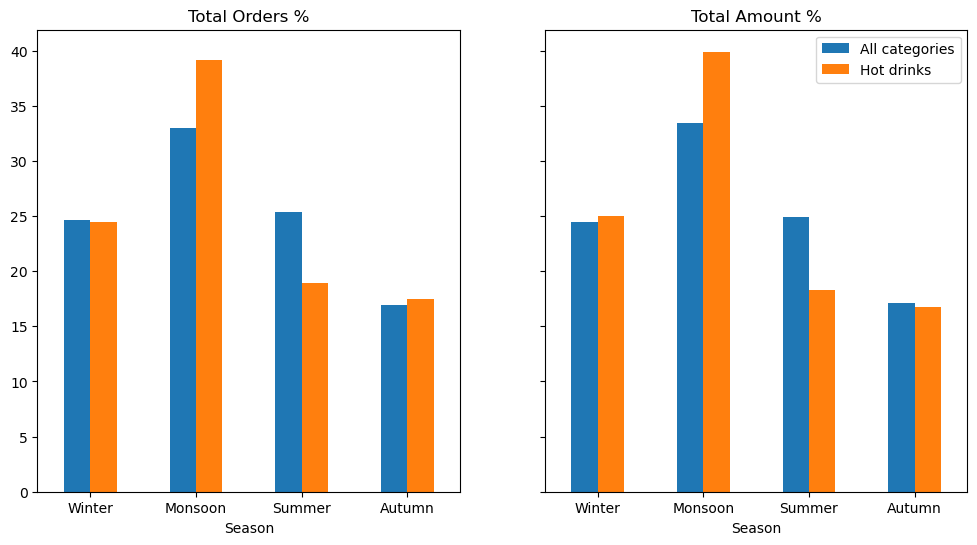

In [30]:
fig, (axes_1, axes_2) = plt.subplots(nrows=1, ncols=2, figsize=(12,6), sharey=True)
seasons_info.plot(kind='bar', x='Season', y=['total_orders_pct', 'total_orders_pct_hot'], rot=0, ax=axes_1, title='Total Orders %', legend=False)
seasons_info.plot(kind='bar', x='Season', y=['total_amount_pct', 'total_amount_pct_hot'], rot=0, ax=axes_2, title='Total Amount %', legend=False)
plt.legend(['All categories', 'Hot drinks'])

In [31]:
hot_orders = df[df['OrderID'].isin(hot_drinks['OrderID'])][['OrderID', 'Product']]    # all orders with hot drinks

hot_pairs_merged = hot_orders.merge(hot_orders, how='inner', on='OrderID', suffixes=('_hot', '_sub'))               # self-merge to create product pairs

hot_pairs_clean = hot_pairs_merged[(hot_pairs_merged['Product_hot'].isin(['Tea', 'Coffee'])) & ~(hot_pairs_merged['Product_sub'].isin(['Tea', 'Coffee']))]   # remove duplicates and invalid pairs

hot_pairs = hot_pairs_clean.groupby(['Product_hot', 'Product_sub'])['Product_sub'].count().reset_index(name='pairs_amount').nlargest(5, 'pairs_amount').reset_index(drop=True)  
# find top products

hot_pairs

,Product_hot,Product_sub,pairs_amount
0,Tea,Biscuit,192
1,Coffee,Muffin,174
2,Coffee,Donut,172
3,Coffee,Chocolate Cake,40
4,Coffee,Cupcake,40
